# Food Access Visualizations
Version 2

**Trace Analysts**

This notebook makes the figures for the analysis. It reads the scored file from the pipeline (`outputs/cook_county_scored.csv`) and builds one chart at a time.

**Data note:** the LRAM data is historical — 2010 tract boundaries and population, 2014-18 ACS figures, and 2019 retailer locations. These charts describe *areas* (census tracts), not individual people, and they are not a 2026 snapshot.

In [1]:
# Import the libraries used throughout the notebook.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

In [2]:
# Path to the scored data created by the pipeline.
# CHANGE THIS PATH IF YOUR FILE IS STORED SOMEWHERE ELSE.
SCORED_PATH = Path("outputs/cook_county_scored.csv")

# CHANGE THESE TWO LINES IF YOUR DATA IS FOR ANOTHER AREA.
STATE_NAME  = "Illinois"
COUNTY_NAME = "Cook County"

# Combine the county and state names into one label for chart titles.
AREA_LABEL = f"{COUNTY_NAME}, {STATE_NAME}"

# Create a folder for saving the finished charts (created automatically if missing).
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

# The six indicators used to calculate the food-access priority score.
INDEX_VARS = [
    "PovertyRate",       # % population below the federal poverty line
    "lapop1share",       # % of tract >1 mi from a supermarket
    "lalowi1share",      # % low-income AND >1 mi from a supermarket
    "lahunv1share",      # % housing units with no vehicle AND >1 mi
    "lasnap1share",      # % SNAP households AND >1 mi
    "MedianFamilyIncome" # inverted in scoring: lower income = higher need
]

# Shorter, easier-to-read names for the charts.
LABELS = {
    "PovertyRate":        "Poverty rate (%)",
    "lapop1share":        "% population >1 mi from supermarket",
    "lalowi1share":       "% low-income & >1 mi",
    "lahunv1share":       "% no-vehicle & >1 mi",
    "lasnap1share":       "% SNAP & >1 mi",
    "MedianFamilyIncome": "Median family income ($)",
    "PriorityScore":      "Priority score (0-1)",
}

# Load the scored CSV into a DataFrame.
df = pd.read_csv(SCORED_PATH)

# Format census tract IDs as 11-digit strings for consistent labeling.
df["CensusTract"] = df["CensusTract"].astype(str).str.split(".").str[0].str.zfill(11)

# Confirm what was loaded.
print(f"Loaded {len(df):,} tracts, {df.shape[1]} columns from {SCORED_PATH}")
print("PriorityScore range:", round(df.PriorityScore.min(), 3), "->", round(df.PriorityScore.max(), 3))

Loaded 1,314 tracts, 21 columns from outputs\cook_county_scored.csv
PriorityScore range: 0.003 -> 0.967


## Figure 1 — Distribution of the six indicators

**What this answers:** this is a supporting figure for the cleaning and scaling step (Acceptance Criterion 1); it is not tied to one research question. We used it to see the shape and spread of each indicator. It also shows why we rescale the variables before scoring. Income runs into the tens of thousands while poverty and the share variables sit on a 0-100 scale, so without rescaling income would dominate the score.

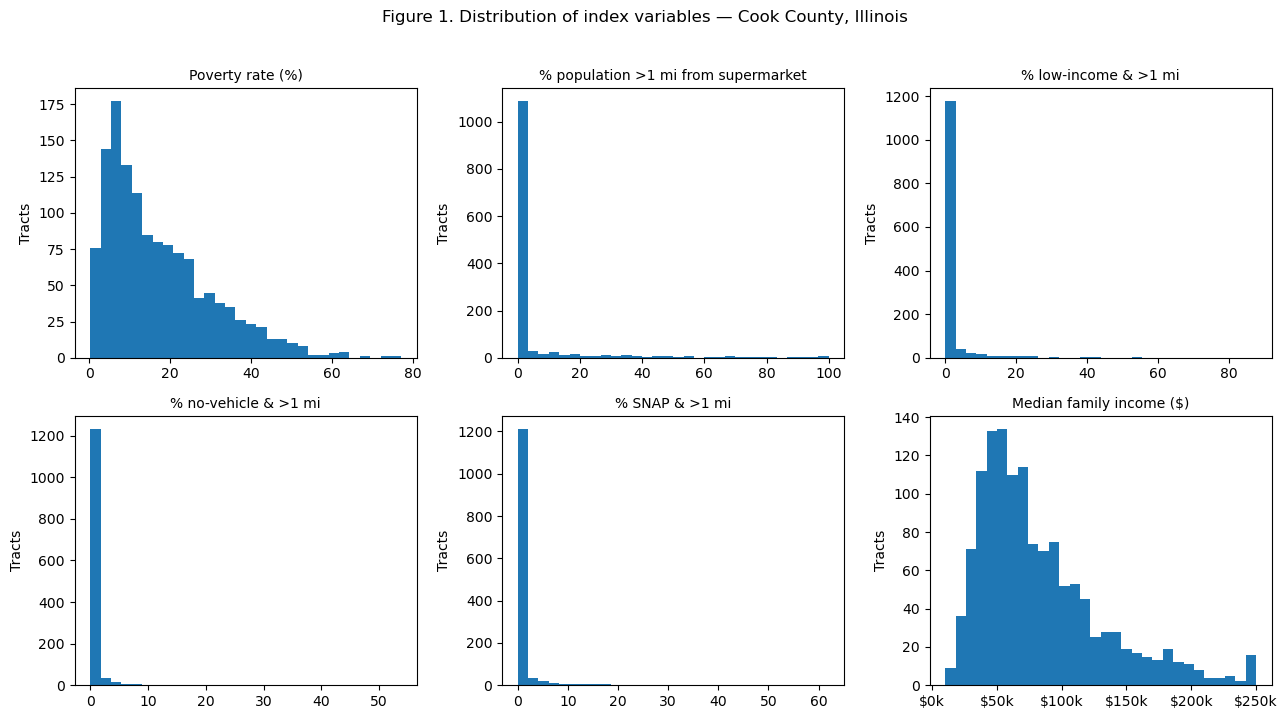

Summary (median / min / max):
  Poverty rate (%)                                 13.5        0.3       77.1
  % population >1 mi from supermarket               0.0        0.0      100.0
  % low-income & >1 mi                              0.0        0.0       87.7
  % no-vehicle & >1 mi                              0.0        0.0       53.9
  % SNAP & >1 mi                                    0.0        0.0       62.0
  Median family income ($)                      69436.0    10131.0   250001.0


In [3]:
# Create six small plots arranged in two rows and three columns.
fig, axes = plt.subplots(2, 3, figsize=(13, 7))

# Draw a histogram for each indicator to show how its values are distributed.
for ax, v in zip(axes.ravel(), INDEX_VARS):
    data = df[v].dropna()
    ax.hist(data, bins=30)
    ax.set_title(LABELS.get(v, v), fontsize=10)
    ax.set_ylabel("Tracts")
    # Show income in thousands of dollars so the axis is easy to read.
    if v == "MedianFamilyIncome":
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))

# Add an overall title, tidy the spacing, save, and display.
fig.suptitle(f"Figure 1. Distribution of index variables — {AREA_LABEL}", fontsize=12, y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_distributions.png", bbox_inches="tight")
plt.show()

# Print a short numeric summary so the finding does not depend on reading the chart.
print("Summary (median / min / max):")
for v in INDEX_VARS:
    s = df[v]
    print(f"  {LABELS.get(v, v):42s} {s.median():10.1f} {s.min():10.1f} {s.max():10.1f}")

## Figure 2 — How many tracts actually have a distance-share value

**What this answers:** another supporting figure for the cleaning step (Acceptance Criterion 1) and the NULL-handling decision. About 77% of tracts have a share of 0 because they are not low-access at one mile — that 0 is a real value, not missing data. We added this chart so the big stack of zeros in Figure 1 is clearly explained and not mistaken for an error.

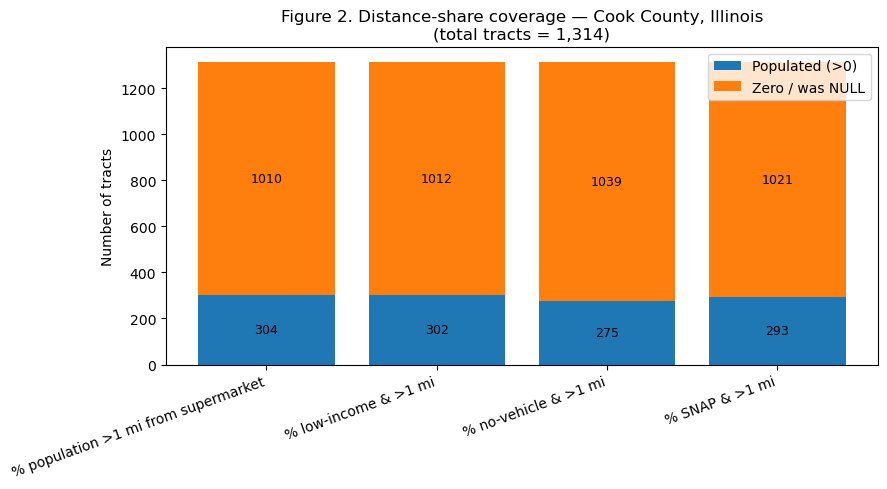

Example: lapop1share populated in 304 of 1314 tracts (23%); 1010 are zero/NULL (77%).


In [4]:
# The four share variables that measure distance from supermarkets.
share_vars = ["lapop1share", "lalowi1share", "lahunv1share", "lasnap1share"]

# Count tracts with a real value (>0) and tracts set to 0 (were NULL) for each.
populated = [(df[v] > 0).sum() for v in share_vars]
zerofill  = [(df[v] == 0).sum() for v in share_vars]

# Positions for the four bars.
x = np.arange(len(share_vars))

# Stacked bars: populated on the bottom, zero/NULL on top. Two groups need two colors.
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x, populated, label="Populated (>0)")
ax.bar(x, zerofill, bottom=populated, label="Zero / was NULL")

# Label the axis, title, and legend.
ax.set_xticks(x); ax.set_xticklabels([LABELS[v] for v in share_vars], rotation=20, ha="right")
ax.set_ylabel("Number of tracts")
ax.set_title(f"Figure 2. Distance-share coverage — {AREA_LABEL}\n(total tracts = {len(df):,})")
ax.legend()

# Write the counts inside each bar section.
for i, (p, z) in enumerate(zip(populated, zerofill)):
    ax.text(i, p/2, str(p), ha="center", va="center", fontsize=9)
    ax.text(i, p + z/2, str(z), ha="center", va="center", fontsize=9)

fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_share_coverage.png", bbox_inches="tight")
plt.show()

# Print one example in words.
print(f"Example: lapop1share populated in {populated[0]} of {len(df)} tracts "
      f"({populated[0]/len(df)*100:.0f}%); {zerofill[0]} are zero/NULL "
      f"({zerofill[0]/len(df)*100:.0f}%).")

## Figure 3 — Top-20 priority tracts

**What this answers:** Question 3 (can a non-technical reader pick out the priority areas) and Acceptance Criterion 2 (a clean ranked output). This is the headline chart — it lists the highest-scoring tracts so someone can read the top priorities straight off the page.

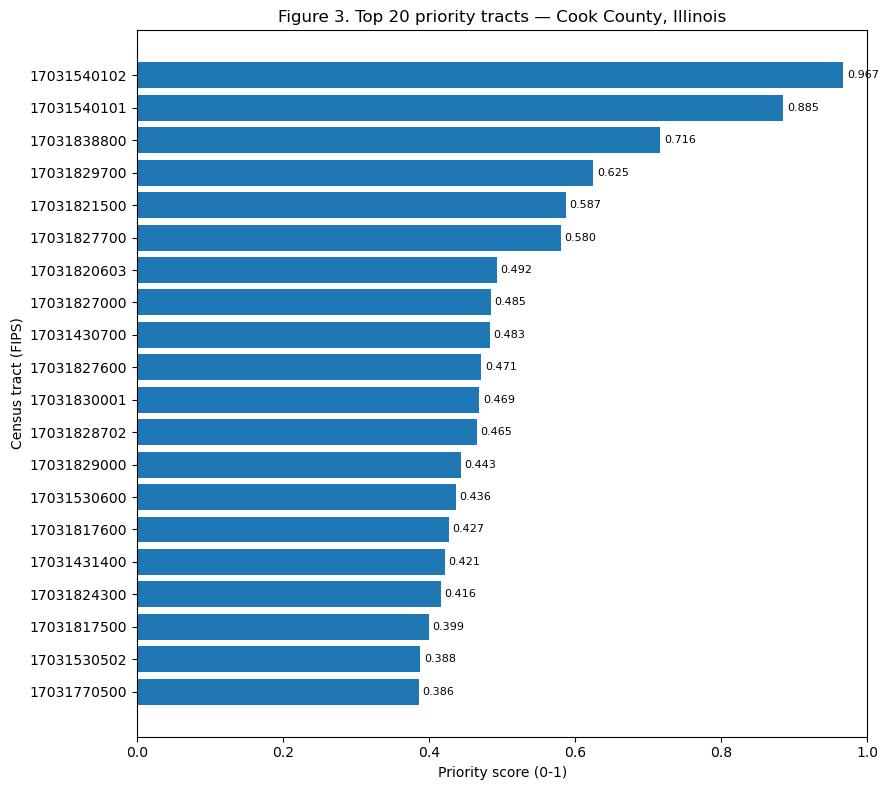

Highest-priority tract: 17031540102 | score 0.967


In [5]:
# Sort by priority score and take the top 20 tracts.
top20 = df.sort_values("PriorityScore", ascending=False).head(20)

# Horizontal bar chart, highest-priority tract at the top.
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top20["CensusTract"], top20["PriorityScore"])
ax.invert_yaxis()

# Axis labels and title.
ax.set_xlabel(LABELS["PriorityScore"])
ax.set_ylabel("Census tract (FIPS)")
ax.set_title(f"Figure 3. Top 20 priority tracts — {AREA_LABEL}")

# Print each score at the end of its bar.
for y, score in enumerate(top20["PriorityScore"]):
    ax.text(score + 0.005, y, f"{score:.3f}", va="center", fontsize=8)

# Leave a little room on the right for the score labels.
ax.set_xlim(0, min(1.0, top20["PriorityScore"].max() + 0.08))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_top20.png", bbox_inches="tight")
plt.show()

# Name the single highest-priority tract.
print("Highest-priority tract:", top20.iloc[0]["CensusTract"],
      "| score", round(top20.iloc[0]["PriorityScore"], 3))

## Figure 4 — Priority score vs. the USDA LILA flag

**What this answers:** Acceptance Criterion 2 — our score compared against the USDA's own low-income/low-access flag (LILATracts_1And10). If the LILA-flagged tracts sit clearly higher, it tells us our score agrees with the USDA's official measure while still giving a finer ranking inside each group. We used a simple boxplot so the two groups are easy to compare.

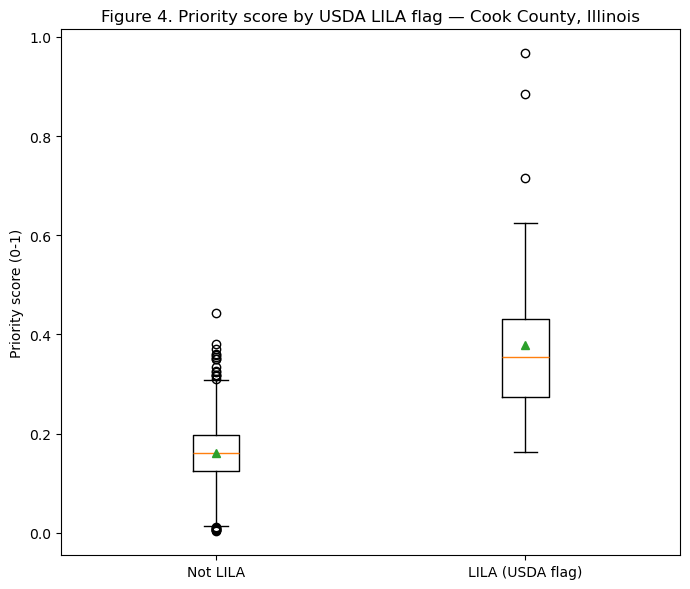

Median priority score — LILA: 0.354 vs non-LILA: 0.161 (LILA tracts: 51)


In [6]:
# This figure needs the USDA LILA flag, which the pipeline now exports.
if "LILATracts_1And10" in df.columns:
    # Split priority scores into the two groups: LILA-flagged vs not.
    groups = [df[df["LILATracts_1And10"] != 1]["PriorityScore"],
              df[df["LILATracts_1And10"] == 1]["PriorityScore"]]

    # Simple side-by-side boxplot comparison.
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.boxplot(groups, tick_labels=["Not LILA", "LILA (USDA flag)"], showmeans=True)
    ax.set_ylabel(LABELS["PriorityScore"])
    ax.set_title(f"Figure 4. Priority score by USDA LILA flag — {AREA_LABEL}")
    fig.tight_layout()
    fig.savefig(FIG_DIR / "fig4_lila_boxplot.png", bbox_inches="tight")
    plt.show()

    # Print the group medians so the comparison is clear in text.
    print(f"Median priority score — LILA: {groups[1].median():.3f} "
          f"vs non-LILA: {groups[0].median():.3f} "
          f"(LILA tracts: {int((df['LILATracts_1And10']==1).sum())})")
else:
    print("LILATracts_1And10 not in file — re-run the pipeline so it is included in the export.")

## Figure 5 — What drives each top tract's score

**What this answers:** the "explain *why* a tract was chosen" part of Question 3, and the transparency goal in Acceptance Criterion 2. We broke each top-15 tract's score into its six parts so a reader can see whether a tract ranks high because of poverty, distance, vehicle access, SNAP, or low income — rather than just trusting the final number.

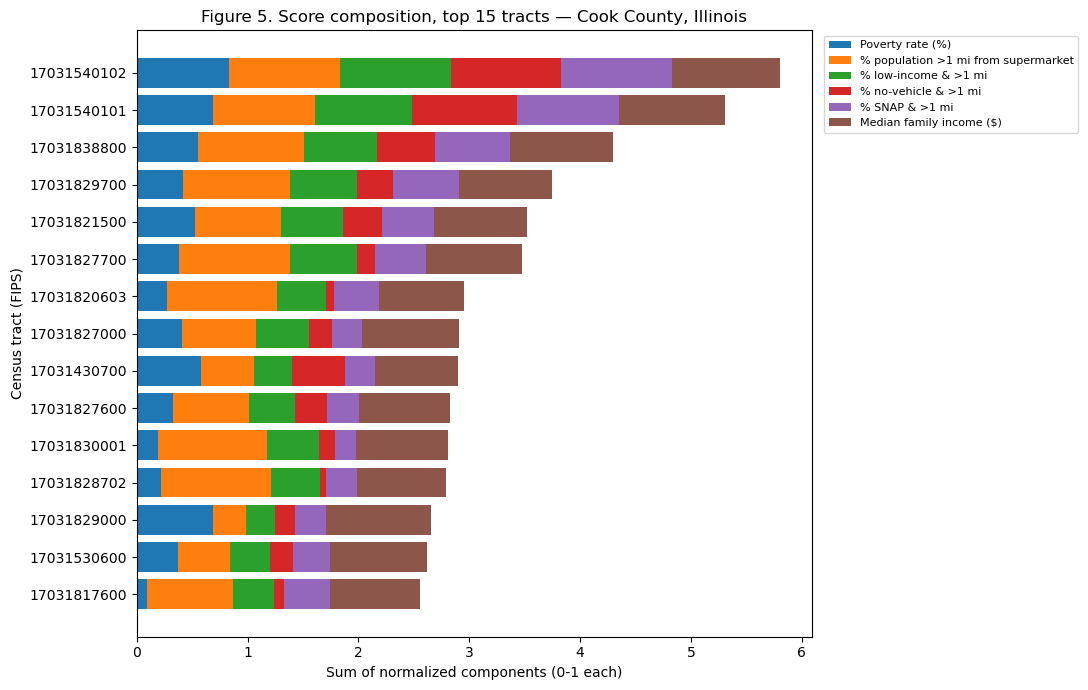

Note: bar length = sum of the six normalized parts; the final PriorityScore is their average.


In [7]:
# Column names for the six normalized components produced by the pipeline.
norm_cols = [v + "_score" for v in INDEX_VARS]

# The 15 highest-priority tracts.
topN = df.sort_values("PriorityScore", ascending=False).head(15)

# Pull their normalized components and label them with the readable variable names.
comp = topN[norm_cols].copy()
comp.columns = INDEX_VARS

# Stacked horizontal bars: one segment per component. Six categories need distinct colors,
# so color here encodes information (which indicator) rather than decoration.
fig, ax = plt.subplots(figsize=(11, 7))
bottom = np.zeros(len(topN))
for v in INDEX_VARS:
    ax.barh(topN["CensusTract"], comp[v].values, left=bottom, label=LABELS.get(v, v))
    bottom += comp[v].values

ax.invert_yaxis()
ax.set_xlabel("Sum of normalized components (0-1 each)")
ax.set_ylabel("Census tract (FIPS)")
ax.set_title(f"Figure 5. Score composition, top 15 tracts — {AREA_LABEL}")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_composition.png", bbox_inches="tight")
plt.show()

print("Note: bar length = sum of the six normalized parts; the final PriorityScore is their average.")

## Figure 6 — Poverty vs. income, colored by priority score

**What this answers:** a supporting check for the scoring behind Questions 1-3. We expected the highest-priority tracts to land in the high-poverty, low-income corner, so this chart is a quick way to confirm the score behaves the way it should. Color shows the priority score and point size shows how many people live in the tract.

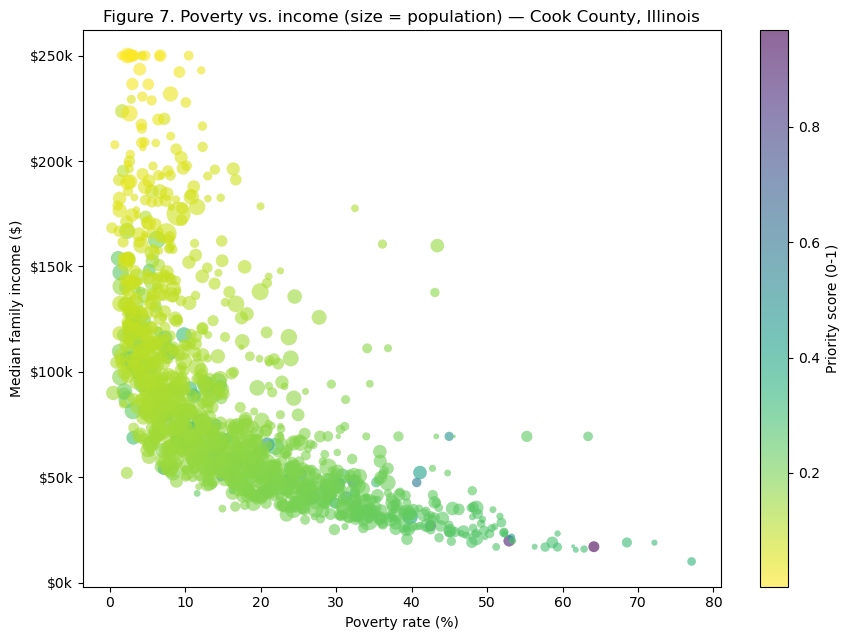

Expect: darker (higher-priority) points cluster in the high-poverty / low-income region.


In [8]:
# Use population for point size if available, otherwise a constant size.
pop = df["Pop2010"] if "Pop2010" in df.columns else pd.Series(50, index=df.index)

# Scatter: poverty (x) vs income (y), color = priority score, size = population.
fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(df["PovertyRate"], df["MedianFamilyIncome"],
                s=np.clip(pop/50, 5, 300), c=df["PriorityScore"],
                cmap="viridis_r", alpha=0.6, edgecolor="none")

# Axis labels, income in thousands, title, and a colorbar for the score.
ax.set_xlabel(LABELS["PovertyRate"])
ax.set_ylabel(LABELS["MedianFamilyIncome"])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
ax.set_title(f"Figure 7. Poverty vs. income (size = population) — {AREA_LABEL}")
fig.colorbar(sc, ax=ax, label=LABELS["PriorityScore"])
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_poverty_income.png", bbox_inches="tight")
plt.show()

print("Expect: darker (higher-priority) points cluster in the high-poverty / low-income region.")

## Figure 7 — Low-access share by vehicle access in high-poverty tracts (Question 1 / Hypothesis 1)
**What this answers:** Question 1 and Hypothesis 1 — among high-poverty tracts, do the ones with worse vehicle access have a higher low-income low-access share than the ones with better vehicle access? 

**A few notes on how to read it:**
- We defined "high poverty" as tracts above the county's median poverty rate, then split that group by the median no-vehicle share into worse vs. better vehicle access. Those cutoffs are a reasonable starting point and can be adjusted if the groups should be defined differently.
- The target from the plan was a gap of at least 10 points in the average low-access share, with p < 0.05.
- We used a Welch t-test, which does not assume the two groups have equal spread.

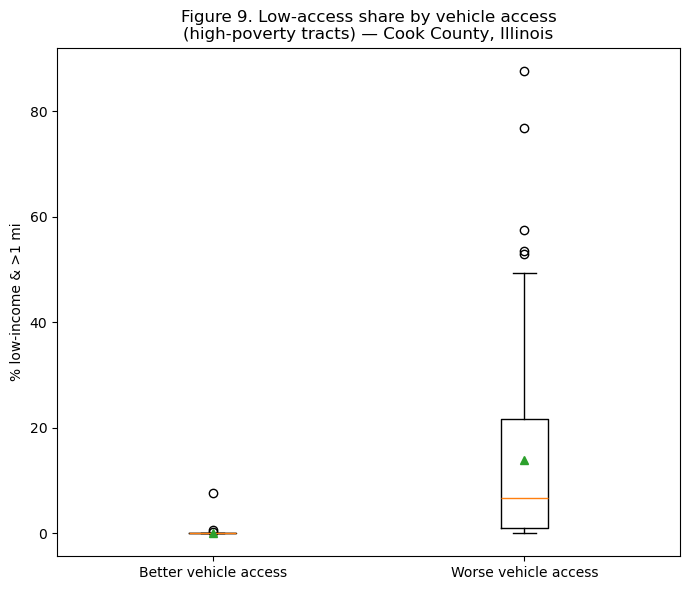

High-poverty tracts (PovertyRate > 13.5): n=657
  Worse vehicle access  mean lalowi1share = 13.91 (n=94)
  Better vehicle access mean lalowi1share = 0.01 (n=563)
  Difference = 13.90 points | Welch t = 7.71, p = 1.36e-11
  Criterion (>=10 pts and p<0.05): MET


In [9]:
# Question 1 / Hypothesis 1: compare lalowi1share by vehicle access within high-poverty tracts.
# Define "high poverty" as above the county median poverty rate.
pov_median = df["PovertyRate"].median()
high_pov = df[df["PovertyRate"] > pov_median].copy()

# Within high-poverty tracts, split by median no-vehicle share.
hunv_median = high_pov["lahunv1share"].median()
low_veh  = high_pov[high_pov["lahunv1share"] >  hunv_median]["lalowi1share"]  # worse vehicle access
high_veh = high_pov[high_pov["lahunv1share"] <= hunv_median]["lalowi1share"]  # better vehicle access

# Welch two-sample t-test (unequal variances). Prefer scipy; fall back to a manual computation.
def welch_ttest(a, b):
    a, b = a.dropna(), b.dropna()
    try:
        from scipy import stats
        t, p = stats.ttest_ind(a, b, equal_var=False)
        return t, p
    except Exception:
        import math
        va, vb, na, nb = a.var(ddof=1), b.var(ddof=1), len(a), len(b)
        t = (a.mean() - b.mean()) / math.sqrt(va/na + vb/nb)
        p = 2 * (1 - 0.5 * (1 + math.erf(abs(t) / math.sqrt(2))))  # normal approx
        return t, p

t_stat, p_val = welch_ttest(low_veh, high_veh)

# Grouped boxplot comparing the two groups.
fig, ax = plt.subplots(figsize=(7, 6))
ax.boxplot([high_veh.dropna(), low_veh.dropna()],
           tick_labels=["Better vehicle access", "Worse vehicle access"], showmeans=True)
ax.set_ylabel(LABELS["lalowi1share"])
ax.set_title(f"Figure 9. Low-access share by vehicle access\n(high-poverty tracts) — {AREA_LABEL}")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig9_q1_vehicle_boxplot.png", bbox_inches="tight")
plt.show()

# Report the group means, the difference, and the test result in words.
diff = low_veh.mean() - high_veh.mean()
print(f"High-poverty tracts (PovertyRate > {pov_median:.1f}): n={len(high_pov)}")
print(f"  Worse vehicle access  mean lalowi1share = {low_veh.mean():.2f} (n={low_veh.notna().sum()})")
print(f"  Better vehicle access mean lalowi1share = {high_veh.mean():.2f} (n={high_veh.notna().sum()})")
print(f"  Difference = {diff:.2f} points | Welch t = {t_stat:.2f}, p = {p_val:.2e}")
print(f"  Criterion (>=10 pts and p<0.05): "
      f"{'MET' if (diff >= 10 and p_val < 0.05) else 'NOT met'}")

## Figure 8 — Distribution of the six indicators

**What this answers:** this is a supporting figure for the cleaning and scaling step (Acceptance Criterion 1); it is not tied to one research question. We used it to see the shape and spread of each indicator. It also shows why we rescale the variables before scoring — income runs into the tens of thousands while poverty and the share variables sit on a 0-100 scale, so without rescaling income would dominate the score.

In [10]:
# Requires a boundary file and geopandas.
GEO_PATH = "tl_2026_17_tract/tl_2026_17_tract.shp"  # e.g. "shapefiles/cb_2019_17_tract_500k.shp"  (Illinois tracts)

# 
if GEO_PATH:
    try:
        import geopandas as gpd
        gdf = gpd.read_file(GEO_PATH)
        gdf["GEOID"] = gdf["GEOID"].astype(str).str.zfill(11)
        # Keep Cook County tracts (state 17 + county 031 -> prefix "17031").
        gdf = gdf[gdf["GEOID"].str.startswith("17031")]
        merged = gdf.merge(df[["CensusTract", "PriorityScore"]],
                           left_on="GEOID", right_on="CensusTract", how="left")
        fig, ax = plt.subplots(figsize=(9, 9))
        merged.plot(column="PriorityScore", cmap="viridis_r", linewidth=0.1,
                    edgecolor="grey", legend=True, ax=ax,
                    legend_kwds={"label": "Priority score (0-1)"},
                    missing_kwds={"color": "lightgrey", "label": "No data"})
        ax.set_title(f"Figure 10. Priority score by census tract — {AREA_LABEL}")
        ax.axis("off")
        fig.savefig(FIG_DIR / "fig10_choropleth.png", bbox_inches="tight", dpi=150)
        plt.show()
        print(f"Mapped {merged['PriorityScore'].notna().sum()} tracts.")
    except ImportError:
        print("geopandas not installed. Run: pip install geopandas, then re-run this cell.")
    except Exception as e:
        print(f"Could not build the map: {e}")
else:
    print("Choropleth skipped — set GEO_PATH to a Cook County tract boundary file to enable it.")

Could not build the map: tl_2026_17_tract/tl_2026_17_tract.shp: No such file or directory


C:\Users\amand\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()
